<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Equation : Salary = 24.400 + 5.455 x Experience
MSE = 0.385   RMSE = 0.621   R2 = 0.9984
Predicted salary for 11 years = 84.40 thousand
Gradient descent: slope = 5.455, intercept = 24.400


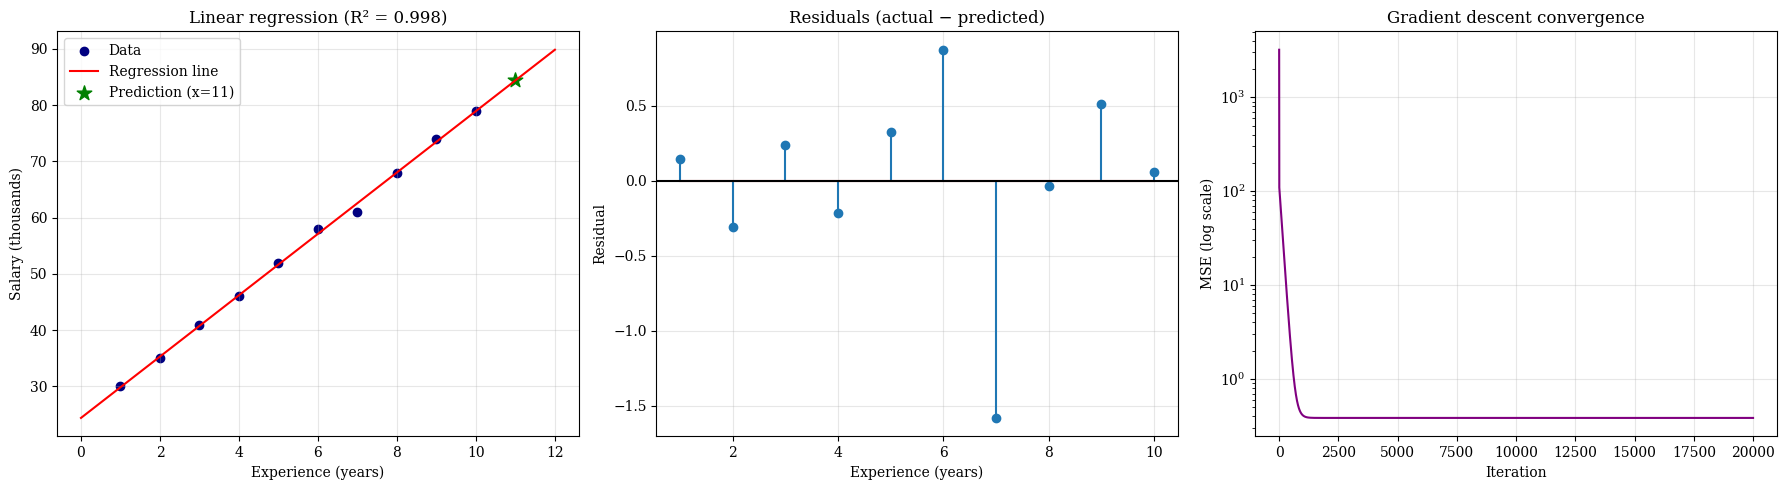

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"

experience = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], dtype=float)         # years
salary     = np.array([30, 35, 41, 46, 52, 58, 61, 68, 74, 79], dtype=float) # thousands

# Least-squares formulas
x_mean, y_mean = experience.mean(), salary.mean()
slope = np.sum((experience - x_mean) * (salary - y_mean)) / np.sum((experience - x_mean) ** 2)
intercept = y_mean - slope * x_mean
y_pred = intercept + slope * experience

mse  = np.mean((salary - y_pred) ** 2)
rmse = np.sqrt(mse)
r2   = 1 - np.sum((salary - y_pred) ** 2) / np.sum((salary - y_mean) ** 2)

print(f"Equation : Salary = {intercept:.3f} + {slope:.3f} x Experience")
print(f"MSE = {mse:.3f}   RMSE = {rmse:.3f}   R2 = {r2:.4f}")
new_x = 11
print(f"Predicted salary for {new_x} years = {intercept + slope * new_x:.2f} thousand")

# Gradient descent (should reach the same line)
w, b, lr, losses = 0.0, 0.0, 0.02, []
for _ in range(20000):
    err = (w * experience + b) - salary
    losses.append(np.mean(err ** 2))
    w -= lr * np.mean(err * experience)
    b -= lr * np.mean(err)
print(f"Gradient descent: slope = {w:.3f}, intercept = {b:.3f}")

# ---- Graphs
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(experience, salary, color="navy", label="Data")
xs = np.linspace(0, 12, 50)
ax[0].plot(xs, intercept + slope * xs, "r-", label="Regression line")
ax[0].scatter([new_x], [intercept + slope * new_x], color="green", s=120, marker="*", label=f"Prediction (x={new_x})")
ax[0].set_xlabel("Experience (years)"); ax[0].set_ylabel("Salary (thousands)")
ax[0].set_title(f"Linear regression (R² = {r2:.3f})"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].stem(experience, salary - y_pred)
ax[1].axhline(0, color="k"); ax[1].set_xlabel("Experience (years)"); ax[1].set_ylabel("Residual")
ax[1].set_title("Residuals (actual − predicted)"); ax[1].grid(alpha=.3)

ax[2].plot(losses, color="purple"); ax[2].set_yscale("log"); ax[2].set_xlabel("Iteration"); ax[2].set_ylabel("MSE (log scale)")
ax[2].set_title("Gradient descent convergence"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()